## Assignment Machine Learning

Masalah: Mengidentifikasi transaksi keuangan ilegal/palsu (Fraudulent) di antara banyak transaksi normal sangatlah sulit dilakukan secara manual karena volume data yang besar dan pola kecurangan yang terus berubah.

Tujuan Model: Memprediksi apakah suatu transaksi masuk ke dalam kategori fraud atau normal secara otomatis berdasarkan berbagai karakteristik transaksi (seperti nominal, lokasi, waktu, metode pembayaran.dll).

Jenis Analisis Prediktif: Saya akan membuat model menggunakan pendekatan Binary Classification (Klasifikasi Biner). Target variabel biner yang diprediksi adalah kolom Fraudulent, dengan ketentuan:
0 = Transaksi Normal, 1 = Transaksi Fraud.

## Data Preparation

In [157]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, RocCurveDisplay

In [158]:
df = pd.read_csv('Transactions Dataset.csv')
df.head()

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
0,T1,4174,1292.76,ATM Withdrawal,16.0,Tablet,San Francisco,0,119,13,Debit Card,0
1,T2,4507,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card,0
2,T3,1860,2395.02,ATM Withdrawal,NaN,Mobile,NaN,3,115,9,NaN,0
3,T4,2294,100.10,Bill Payment,15.0,Desktop,Chicago,4,3,4,UPI,0
4,T5,2130,1490.50,POS Payment,19.0,Mobile,San Francisco,2,57,7,Credit Card,0


## Fitur-Fitur (Features):
1. Transaction_ID: Identifikasi unik string untuk setiap transaksi (misal: T1, T2, T3). Fitur ini bertindak sebagai Primary Key dan tidak memiliki nilai prediktif.
2. User_ID: Identifikasi unik untuk pengguna/pemilik akun yang melakukan transaksi.
3. Transaction_Amount: Nominal uang yang dikeluarkan atau ditransfer dalam transaksi tersebut.
4. Transaction_Type: Jenis transaksi yang dilakukan (contoh: ATM Withdrawal, Bill Payment, POS Payment).
5. Time_of_Transaction: Waktu terjadinya transaksi dalam format jam (0–23).
6. Device_Used: Jenis perangkat yang digunakan oleh pengguna saat bertransaksi (contoh: Tablet, Mobile, Desktop).
7. Location: Kota lokasi tempat transaksi tersebut dilakukan (contoh: San Francisco, New York, Chicago).
8. Previous_Fraudulent_Transactions: Jumlah transaksi fraud yang pernah tercatat dilakukan oleh akun ini sebelumnya.
9. Account_Age: Usia akun pengguna dalam hitungan bulan.
10. Number_of_Transactions_Last_24H: Frekuensi/jumlah transaksi yang dilakukan pengguna dalam 24 jam terakhir.
11. Payment_Method: Metode pembayaran yang digunakan (contoh: Debit Card, Credit Card, UPI).
12. Fraudulent (Target Variabel): Indikator apakah transaksi tersebut merupakan penipuan atau bukan. Berupa variabel biner: 0 = Transaksi Normal, 1 = Transaksi Fraud.

## Exploratory Data Analysis (EDA)

In [159]:
df.shape

(51000, 12)

In [160]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51000 entries, 0 to 50999
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Transaction_ID                    51000 non-null  object 
 1   User_ID                           51000 non-null  int64  
 2   Transaction_Amount                48480 non-null  float64
 3   Transaction_Type                  51000 non-null  object 
 4   Time_of_Transaction               48448 non-null  float64
 5   Device_Used                       48527 non-null  object 
 6   Location                          48453 non-null  object 
 7   Previous_Fraudulent_Transactions  51000 non-null  int64  
 8   Account_Age                       51000 non-null  int64  
 9   Number_of_Transactions_Last_24H   51000 non-null  int64  
 10  Payment_Method                    48531 non-null  object 
 11  Fraudulent                        51000 non-null  int64  
dtypes: f

In [161]:
df.columns

Index(['Transaction_ID', 'User_ID', 'Transaction_Amount', 'Transaction_Type',
       'Time_of_Transaction', 'Device_Used', 'Location',
       'Previous_Fraudulent_Transactions', 'Account_Age',
       'Number_of_Transactions_Last_24H', 'Payment_Method', 'Fraudulent'],
      dtype='object')

In [162]:
df.dtypes

Transaction_ID                       object
User_ID                               int64
Transaction_Amount                  float64
Transaction_Type                     object
Time_of_Transaction                 float64
Device_Used                          object
Location                             object
Previous_Fraudulent_Transactions      int64
Account_Age                           int64
Number_of_Transactions_Last_24H       int64
Payment_Method                       object
Fraudulent                            int64
dtype: object

In [163]:
df.describe()

,User_ID,Transaction_Amount,Time_of_Transaction,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Fraudulent
count,51000.000000,48480.000000,48448.000000,51000.000000,51000.000000,51000.000000,51000.000000
mean,3005.110176,2996.249784,11.488400,1.995725,60.033902,7.495588,0.049216
std,1153.121107,5043.932555,6.922954,1.415150,34.384131,4.020080,0.216320
min,1000.000000,5.030000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,2007.000000,1270.552500,5.000000,1.000000,30.000000,4.000000,0.000000
50%,2996.000000,2524.100000,12.000000,2.000000,60.000000,7.000000,0.000000
75%,4006.000000,3787.240000,17.000000,3.000000,90.000000,11.000000,0.000000
max,4999.000000,49997.800000,23.000000,4.000000,119.000000,14.000000,1.000000


Dataset ini memiliki ukuran asli 51.000 baris dan 12 kolom. Karakteristik datanya meliputi kombinasi tipe numerik (float64, int64) dan kategori (object).

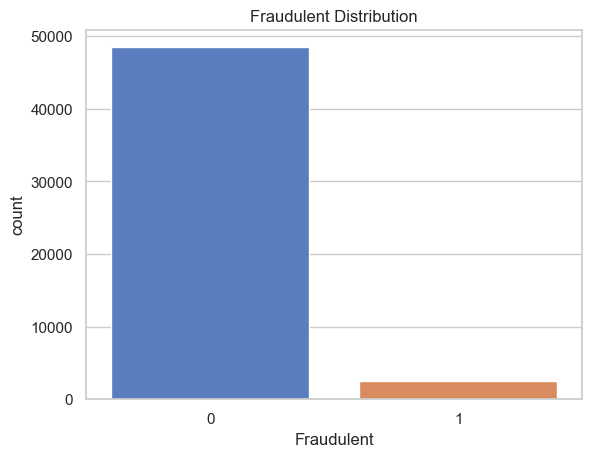

In [164]:
sns.countplot(x='Fraudulent', data=df)
plt.title('Fraudulent Distribution')
plt.show()

In [165]:
df['Fraudulent'].value_counts(normalize=True)*100

Fraudulent
0    95.078431
1     4.921569
Name: proportion, dtype: float64

In [166]:
df['Fraudulent'].value_counts()

Fraudulent
0    48490
1     2510
Name: count, dtype: int64

# Dataset sangat imbalance karena Non Fraud = 95.0784% dan Fraud = 4.9216%. Model Machine Learning yang dibuat tanpa penanganan imbalance akan cenderung mengalami bias. Model tersebut akan menebak semua transaksi sebagai "Normal" dan tetap mendapatkan akurasi tinggi (~95%), tetapi gagal total dalam mendeteksi transaksi fraud (Recall untuk kelas 1 akan sangat rendah).

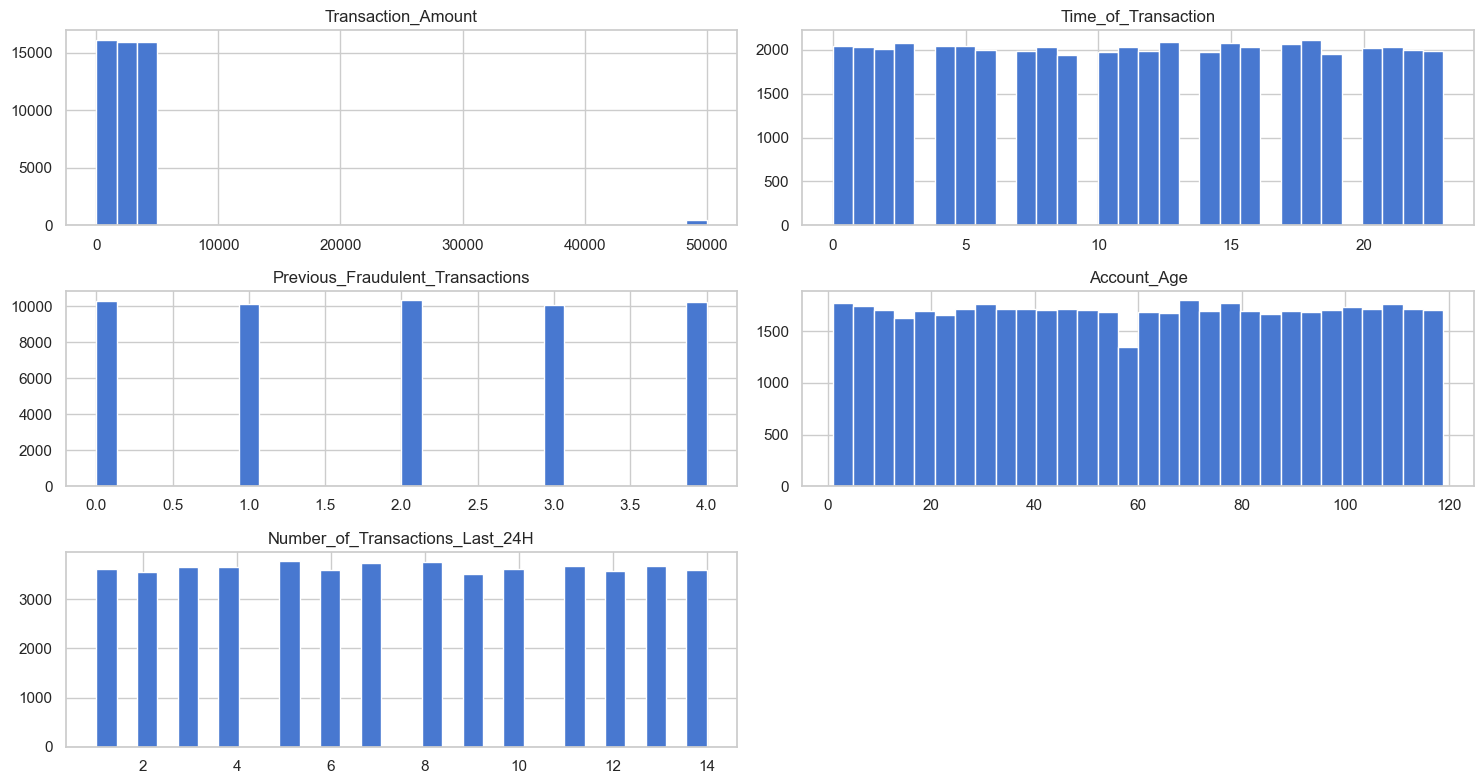

In [167]:
# Melihat distribusi

num_cols = [
    'Transaction_Amount',
    'Time_of_Transaction',
    'Previous_Fraudulent_Transactions',
    'Account_Age',
    'Number_of_Transactions_Last_24H'
]

df[num_cols].hist(
    figsize=(15,8),
    bins=30
)

plt.tight_layout()
plt.show()

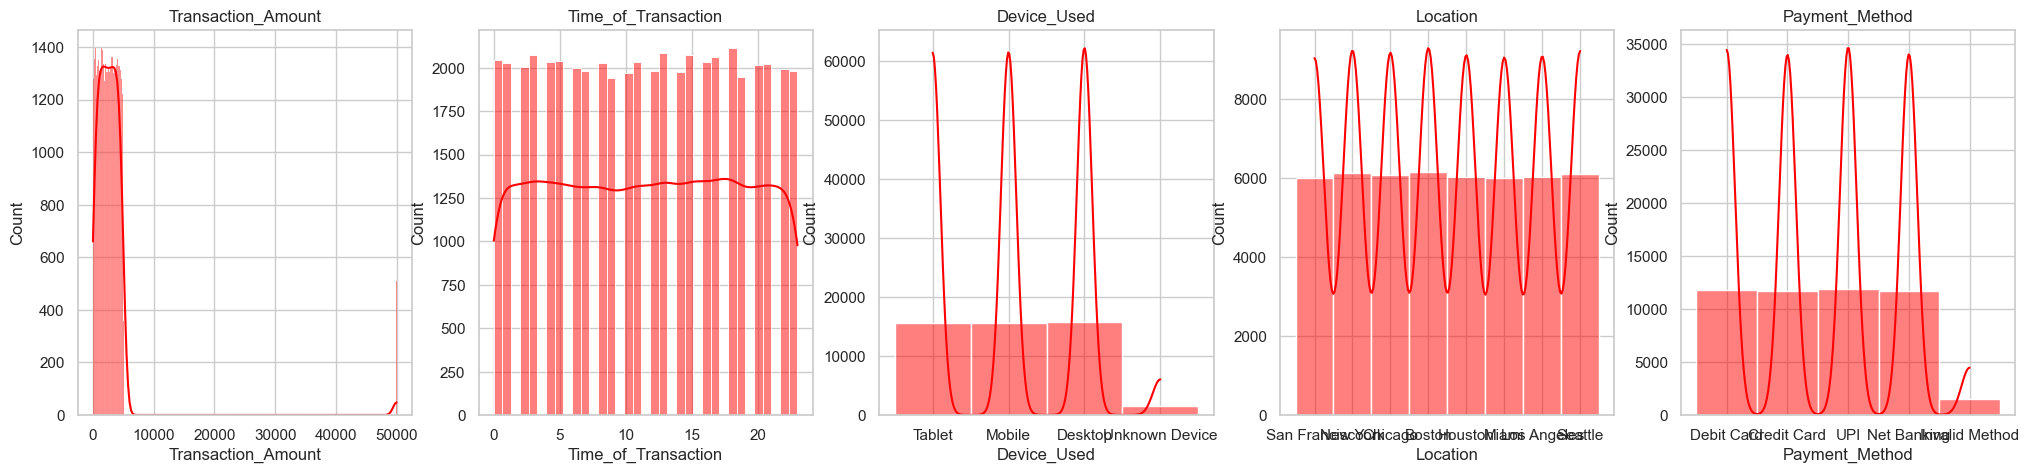

<Figure size 2000x2000 with 0 Axes>

In [168]:
missing_cols = [col for col in df.columns if df[col].isnull().sum() > 0]

fig, axes = plt.subplots(1, len(missing_cols), figsize=(5 * len(missing_cols), 5))

if len(missing_cols) == 1:
    axes = [axes]

for ax, col in zip(axes, missing_cols):
    sns.histplot(df[col], kde=True, ax=ax, color='red')
    ax.set_title(col)

plt.figure(figsize=(20, 20))
plt.tight_layout()
plt.show()

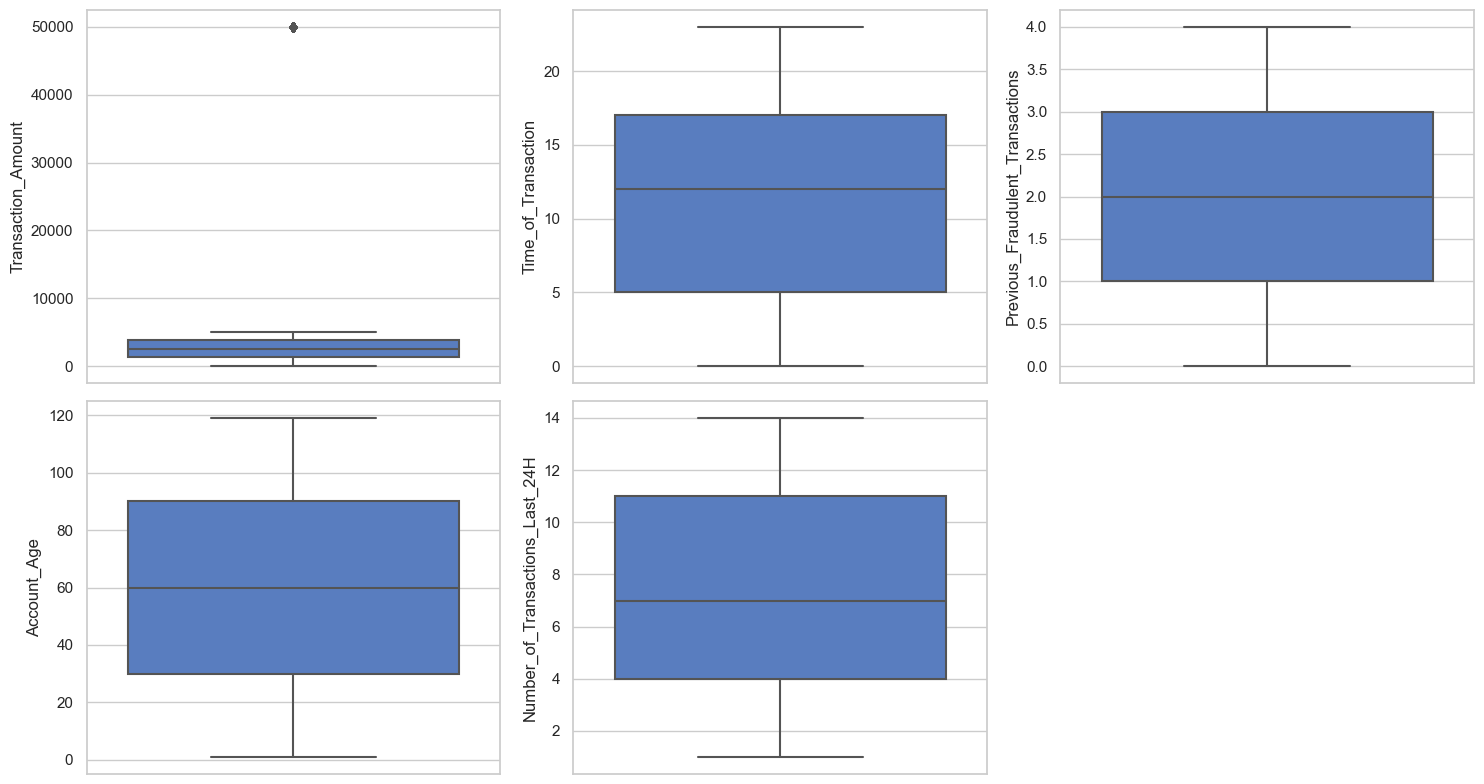

In [169]:
plt.figure(figsize=(15,8))

for i,col in enumerate(num_cols):
    plt.subplot(2,3,i+1)
    sns.boxplot(y=df[col])

plt.tight_layout()
plt.show()

<Axes: ylabel='Transaction_Amount'>

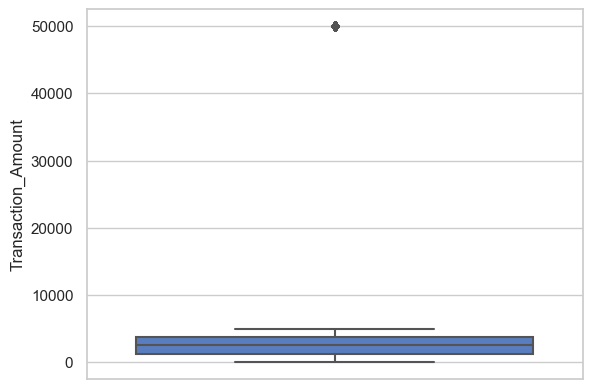

In [170]:
# Terdapat banyak outlier nominal transaksi di area tertentu.
sns.boxplot(y=df['Transaction_Amount'])

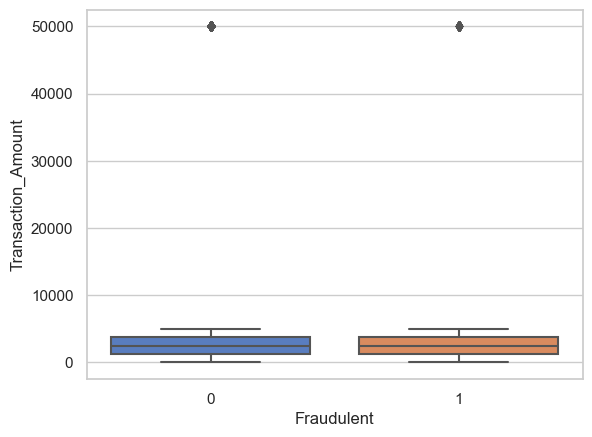

In [171]:
# Untuk melihat apakah fraud cenderung memiliki nominal tertentu.
sns.boxplot(
    x='Fraudulent',
    y='Transaction_Amount',
    data=df
)

plt.show()

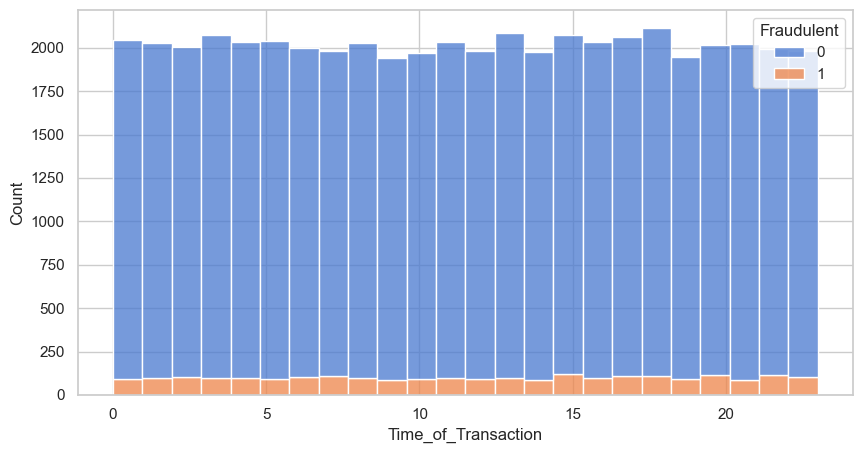

In [172]:
# Cek apakah fraud lebih banyak terjadi malam hari.
plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x='Time_of_Transaction',
    hue='Fraudulent',
    bins=24,
    multiple='stack'
)

plt.show()

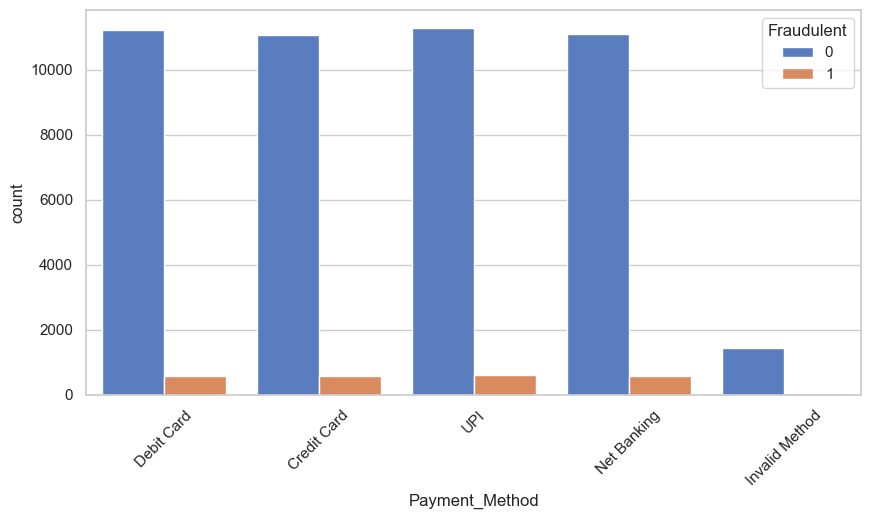

In [173]:
# Cek apakah fraud terkait metode pembayaran.
plt.figure(figsize=(10,5))

sns.countplot(
    x='Payment_Method',
    hue='Fraudulent',
    data=df
)

plt.xticks(rotation=45)
plt.show()

<Axes: xlabel='Device_Used', ylabel='count'>

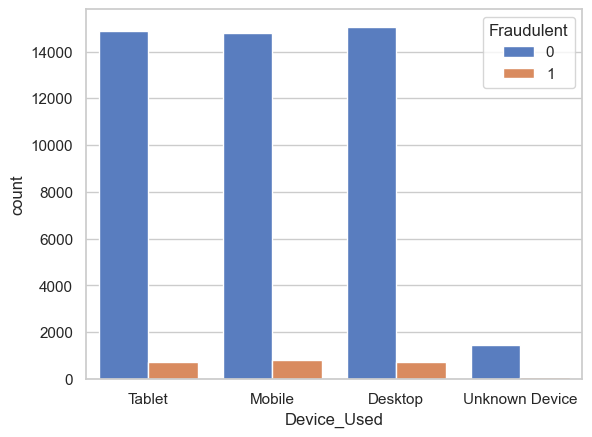

In [174]:
# Cek apakah fraud berkaitan dengan device
sns.countplot(
    x='Device_Used',
    hue='Fraudulent',
    data=df
)

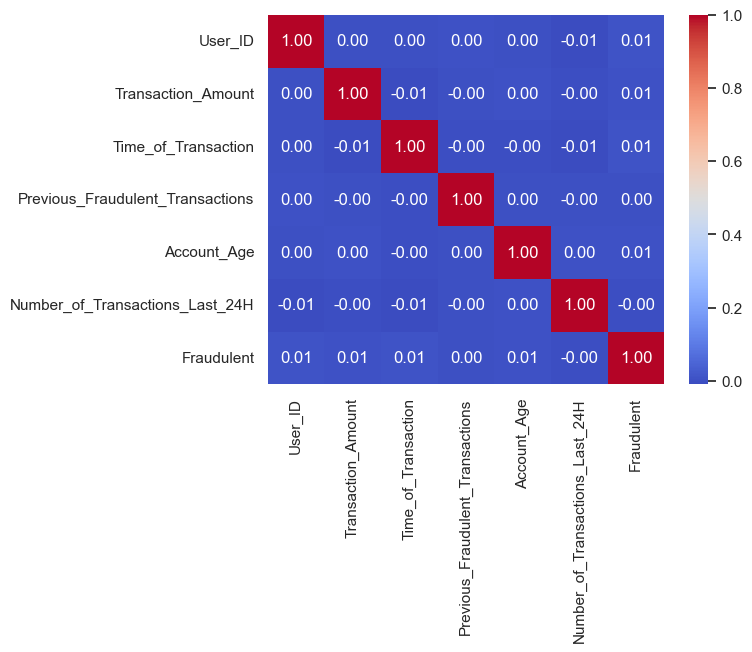

In [175]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

Korelasi fitur terhadap target sangat rendah bahkan hampir tidak ada. Hal ini kemungkinan besar disebabkan oleh keacakan data atau adanya outlier sehingga fitur-fitur tidak saling berkolerasi satu sama lain.

In [176]:
for column in df.columns : # skew() yang baik itu mendekati 0, .kurt() yang baik itu mendekati 3
    if df[column].dtype != "object": 
        skewness = df[column].skew()
        kurtosis = df[column].kurt()
        print(f"Column: {column:25} | Skewness: {skewness:8.4f} | Kurtosis: {kurtosis:8.4f}")

Column: User_ID                   | Skewness:  -0.0016 | Kurtosis:  -1.2012
Column: Transaction_Amount        | Skewness:   8.4545 | Kurtosis:  76.0361
Column: Time_of_Transaction       | Skewness:  -0.0044 | Kurtosis:  -1.2073
Column: Previous_Fraudulent_Transactions | Skewness:   0.0044 | Kurtosis:  -1.2988
Column: Account_Age               | Skewness:  -0.0030 | Kurtosis:  -1.1971
Column: Number_of_Transactions_Last_24H | Skewness:   0.0052 | Kurtosis:  -1.2054
Column: Fraudulent                | Skewness:   4.1679 | Kurtosis:  15.3721


1. Kolom dengan Distribusi Normal (Simetris & Landai)
Kolom-kolom berikut memiliki nilai Skewness mendekati 0 (sangat simetris) dan Kurtosis di bawah 3 (tepatnya sekitar -1.2, yang berarti distribusinya datar atau Platykurtic tanpa penumpukan ekstrem):
User_ID, Time_of_Transaction, Previous_Fraudulent_Transactions, Account_Age, Number_of_Transactions_Last_24H.
Arti: Data pada kolom-kolom ini tersebar merata secara acak/seragam dari nilai terendah hingga tertinggi, serta tidak memiliki masalah pencilan (outlier) yang ekstrem.

2. Transaction_Amount (Nominal Transaksi) — Sangat Tidak Normal / Skewed Ekstrem
Skewness (8.4545): Nilai positif yang sangat tinggi. Berarti data miring tajam ke kanan (highly right-skewed). Kurtosis (76.0361): Jauh di atas angka 3 (Leptokurtic ekstrem).
Arti: Mayoritas transaksi di dataset bernilai kecil atau sedang, tetapi ada beberapa transaksi dengan nominal raksasa (outlier masif) yang menarik ujung kurva menjadi sangat panjang ke kanan.

3. Fraudulent (Variabel Target) — Sangat Tidak Seimbang
Skewness (4.1679) & Kurtosis (15.3721) yang tinggi pada kolom biner (0 dan 1) bukan menandakan bentuk kurva kontinu, melainkan bentuk visualisasi dari Imbalanced Data.
Arti: Angka ini mengonfirmasi secara matematis bahwa label 0 (Transaksi Normal) mendominasi secara mutlak, sedangkan label 1 (Transaksi Fraud) jumlahnya sangat sedikit (hanya sekitar ~5% dari total data). Model akan kesulitan mempelajari pola dari kelas yang sangat langka ini.

Hasil EDA menunjukkan bahwa kumpulan data memiliki label variabel target yang tidak seimbang. Ketidakseimbangan data ini dapat diatasi melalui beberapa pendekatan seperti:

- Oversampling Kelas Minoritas dengan SMOTE (Synthetic Minority Over-sampling Technique): Metode paling ideal untuk ukuran dataset yang kecil. Dilakukan hanya pada data training agar tidak terjadi data leakage.

- Undersampling Kelas Mayoritas: Pendekatan yang cepat namun memiliki risiko kehilangan informasi penting.

- Penyesuaian Bobot Kelas (Class Weights): Solusi terbaik dan paling efisien untuk menangani data skala besar.

- Deteksi Anomali: Teknik khusus yang biasanya diterapkan untuk kasus deteksi penipuan (fraud) atau kegagalan sistem.


## Data Preprocessing

In [177]:
df.isnull().sum()

Transaction_ID                         0
User_ID                                0
Transaction_Amount                  2520
Transaction_Type                       0
Time_of_Transaction                 2552
Device_Used                         2473
Location                            2547
Previous_Fraudulent_Transactions       0
Account_Age                            0
Number_of_Transactions_Last_24H        0
Payment_Method                      2469
Fraudulent                             0
dtype: int64

In [178]:
df.duplicated().sum()

881

In [179]:
# Fill missing values

missing_percentage = df.isna().sum() / len(df) * 100
print(missing_percentage) #Kalau ada kolom yang persentase nya lebih dari 50, hapus aja

for key, value in missing_percentage.items() : 
	if(value > 50.0) : 
		df = df.drop(columns = [key], axis = 1)
		
num_cols = [
    'Transaction_Amount',
    'Time_of_Transaction'
]

df['Transaction_Amount'] = df['Transaction_Amount'].fillna(
    df['Transaction_Amount'].median()
)

df['Time_of_Transaction'] = df['Time_of_Transaction'].fillna(
    df['Time_of_Transaction'].median()
)

cat_cols = [
    'Transaction_Type',
    'Device_Used',
    'Location',
    'Payment_Method'
]

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])
	
# Kolom numerik diimputasi dengan nilai Median untuk menghindari dampak sebaran outlier.
# Kolom kategorikal diimputasi dengan nilai Modus (kategori yang paling sering muncul).

Transaction_ID                      0.000000
User_ID                             0.000000
Transaction_Amount                  4.941176
Transaction_Type                    0.000000
Time_of_Transaction                 5.003922
Device_Used                         4.849020
Location                            4.994118
Previous_Fraudulent_Transactions    0.000000
Account_Age                         0.000000
Number_of_Transactions_Last_24H     0.000000
Payment_Method                      4.841176
Fraudulent                          0.000000
dtype: float64


In [180]:
df.isnull().sum()

Transaction_ID                      0
User_ID                             0
Transaction_Amount                  0
Transaction_Type                    0
Time_of_Transaction                 0
Device_Used                         0
Location                            0
Previous_Fraudulent_Transactions    0
Account_Age                         0
Number_of_Transactions_Last_24H     0
Payment_Method                      0
Fraudulent                          0
dtype: int64

In [181]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51000 entries, 0 to 50999
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Transaction_ID                    51000 non-null  object 
 1   User_ID                           51000 non-null  int64  
 2   Transaction_Amount                51000 non-null  float64
 3   Transaction_Type                  51000 non-null  object 
 4   Time_of_Transaction               51000 non-null  float64
 5   Device_Used                       51000 non-null  object 
 6   Location                          51000 non-null  object 
 7   Previous_Fraudulent_Transactions  51000 non-null  int64  
 8   Account_Age                       51000 non-null  int64  
 9   Number_of_Transactions_Last_24H   51000 non-null  int64  
 10  Payment_Method                    51000 non-null  object 
 11  Fraudulent                        51000 non-null  int64  
dtypes: f

In [182]:
print("Unique Data of Transaction_ID:", len(df['Transaction_ID'].unique()))
print("Unique Data Of User_ID:", len(df['User_ID'].unique()))

Unique Data of Transaction_ID: 50000
Unique Data Of User_ID: 4000


In [183]:
df.drop(columns=['Transaction_ID'], inplace = True)
# Fitur Transaction_ID tidak berkontribusi pada akurasi prediksi model dan berisiko menimbulkan noise, sehingga fitur tersebut dihapus. 
# Sebaliknya, User_ID tetap dipertahankan karena menyediakan data kontekstual yang bermanfaat.
# Setiap peristiwa penipuan biasanya dikaitkan dengan satu akun, fitur ini menjadi kunci penting bagi model.

In [184]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51000 entries, 0 to 50999
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   User_ID                           51000 non-null  int64  
 1   Transaction_Amount                51000 non-null  float64
 2   Transaction_Type                  51000 non-null  object 
 3   Time_of_Transaction               51000 non-null  float64
 4   Device_Used                       51000 non-null  object 
 5   Location                          51000 non-null  object 
 6   Previous_Fraudulent_Transactions  51000 non-null  int64  
 7   Account_Age                       51000 non-null  int64  
 8   Number_of_Transactions_Last_24H   51000 non-null  int64  
 9   Payment_Method                    51000 non-null  object 
 10  Fraudulent                        51000 non-null  int64  
dtypes: float64(2), int64(5), object(4)
memory usage: 4.3+ MB


In [185]:
# Encoding
# Untuk EDA, LabelEncoder digunakan untuk melihat opsi sepenuhnya. Jenis pengkodean lainnya akan membuat terlalu banyak kolom, sehingga mengacaukan statistik. 
# Untuk pemodelannya dapat menggunakan OneHotEncoding. 
encoder = LabelEncoder()

categorical_features = ['Transaction_Type', 'Device_Used', 'Location', 'Payment_Method']

for col in categorical_features:
    df[col] = encoder.fit_transform(df[col])

# One-hot encoding
df = pd.get_dummies(
    df,
    columns=cat_cols,
    drop_first=True
)

In [186]:
# train-test split
X = df.drop('Fraudulent', axis=1)
y = df['Fraudulent']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [187]:
# scaling 
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Logistic Regression (LR): Menggunakan rumus matematika linear dan jarak. Jika data tidak disamakan skalanya (scaling), kolom dengan angka besar (seperti nominal uang jutaan) akan mendominasi model dan membuat proses hitung jadi berantakan atau lambat. Jadi, wajib di-scale.

Random Forest (RF) & Decision Tree (DT): Bekerja seperti pohon keputusan bercabang (if-else). Model ini hanya melihat urutan nilai untuk memotong data (misal: "apakah nilai > 5000?"). Karena di-scale ataupun tidak urutan datanya tetap sama, hasil tebakan tidak akan berubah sama sekali. Jadi, tidak perlu di-scale.

In [188]:
print(df.isnull().sum())

User_ID                             0
Transaction_Amount                  0
Time_of_Transaction                 0
Previous_Fraudulent_Transactions    0
Account_Age                         0
Number_of_Transactions_Last_24H     0
Fraudulent                          0
Transaction_Type_1                  0
Transaction_Type_2                  0
Transaction_Type_3                  0
Transaction_Type_4                  0
Device_Used_1                       0
Device_Used_2                       0
Device_Used_3                       0
Location_1                          0
Location_2                          0
Location_3                          0
Location_4                          0
Location_5                          0
Location_6                          0
Location_7                          0
Payment_Method_1                    0
Payment_Method_2                    0
Payment_Method_3                    0
Payment_Method_4                    0
dtype: int64


## Modelling

In [189]:
lr = LogisticRegression(
    class_weight='balanced',
    max_iter=1000
)

lr.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [190]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced',
    random_state=42
)

rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=10, n_estimators=200,
                       random_state=42)

In [191]:
dt = DecisionTreeClassifier(
    max_depth=10,
    class_weight='balanced',
    random_state=42
)

dt.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=10, random_state=42)

## Evaluation

Dalam kasus fraud detection, metrik Accuracy saja tidak cukup. Jika model menebak semua transaksi sebagai "Normal (0)", akurasi model akan tetap tinggi (~95%), namun model gagal total dalam mendeteksi fraud. Oleh karena itu, evaluasi juga akan menggunakan metrik:
- Precision: Dari seluruh transaksi yang ditebak fraud oleh model, berapa banyak yang benar-benar fraud. (Penting untuk menjaga kenyamanan pengguna agar transaksi normal tidak sering terblokir secara salah/False Positive).
- Recall (Sensitivity): Seberapa banyak transaksi fraud asli yang berhasil ditangkap oleh model. (Sangat krusial, karena kita tidak ingin meloloskan transaksi fraud).
- F1-Score: Rata-rata harmonik antara Precision dan Recall.
- ROC-AUC Score: Mengukur kemampuan model dalam memisahkan kedua kelas secara keseluruhan.

In [192]:
def evaluate_model(
    model,
    X_test,
    y_test,
    model_name
):

    pred = model.predict(X_test)

    prob = model.predict_proba(X_test)[:,1]

    acc = accuracy_score(y_test,pred)
    prec = precision_score(y_test,pred)
    rec = recall_score(y_test,pred)
    f1 = f1_score(y_test,pred)
    auc = roc_auc_score(y_test,prob)

    print(f"\n=== {model_name} ===")

    print(classification_report(
        y_test,
        pred
    ))

    print(f"Accuracy : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1 Score : {f1:.4f}")
    print(f"ROC AUC  : {auc:.4f}")

    return [
        model_name,
        acc,
        prec,
        rec,
        f1,
        auc
    ]

In [193]:
lr_result = evaluate_model(
    lr,
    X_test_scaled,
    y_test,
    "Logistic Regression"
)


=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.95      0.54      0.69      9698
           1       0.05      0.42      0.08       502

    accuracy                           0.54     10200
   macro avg       0.50      0.48      0.39     10200
weighted avg       0.90      0.54      0.66     10200

Accuracy : 0.5365
Precision : 0.0458
Recall   : 0.4243
F1 Score : 0.0827
ROC AUC  : 0.4927


In [194]:
rf_result = evaluate_model(
    rf,
    X_test,
    y_test,
    "Random Forest"
)


=== Random Forest ===
              precision    recall  f1-score   support

           0       0.95      0.97      0.96      9698
           1       0.09      0.05      0.06       502

    accuracy                           0.93     10200
   macro avg       0.52      0.51      0.51     10200
weighted avg       0.91      0.93      0.92     10200

Accuracy : 0.9265
Precision : 0.0867
Recall   : 0.0518
F1 Score : 0.0648
ROC AUC  : 0.5163


In [195]:
dt_result = evaluate_model(
    dt,
    X_test,
    y_test,
    "Decision Tree"
)


=== Decision Tree ===
              precision    recall  f1-score   support

           0       0.95      0.62      0.75      9698
           1       0.05      0.40      0.09       502

    accuracy                           0.61     10200
   macro avg       0.50      0.51      0.42     10200
weighted avg       0.91      0.61      0.72     10200

Accuracy : 0.6061
Precision : 0.0515
Recall   : 0.4024
F1 Score : 0.0914
ROC AUC  : 0.5154


In [196]:
results_df = pd.DataFrame(
    [
        lr_result,
        rf_result,
        dt_result
    ],
    columns=[
        'Model',
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'ROC_AUC'
    ]
)

results_df.sort_values(
    by='ROC_AUC',
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC_AUC
1,Random Forest,0.926471,0.086667,0.051793,0.064838,0.516298
2,Decision Tree,0.606078,0.051531,0.402390,0.091361,0.515444
0,Logistic Regression,0.536471,0.045787,0.424303,0.082654,0.492699


In [197]:
def plot_cm(
    model,
    X_test,
    y_test,
    title
):

    pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        pred
    )

    plt.figure(figsize=(6,4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )

    plt.title(title)

    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

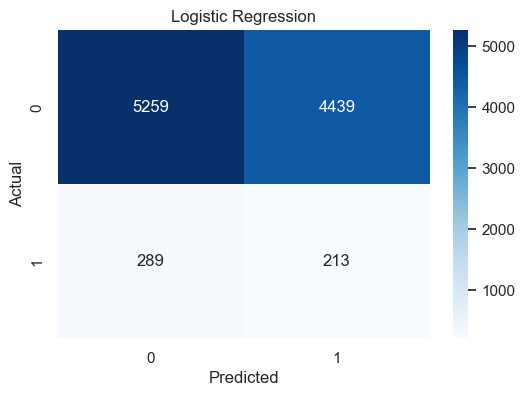

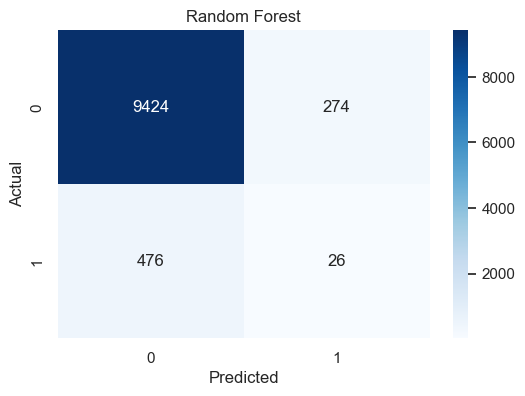

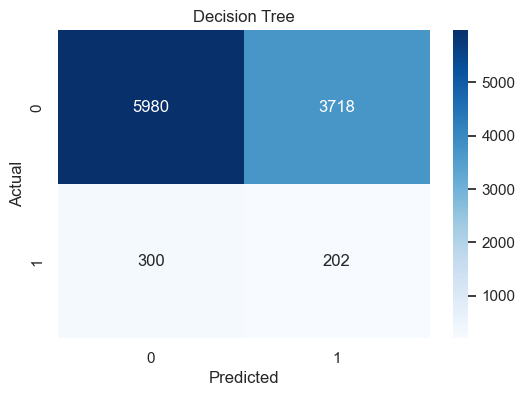

In [198]:
plot_cm(
    lr,
    X_test_scaled,
    y_test,
    "Logistic Regression"
)

plot_cm(
    rf,
    X_test,
    y_test,
    "Random Forest"
)

plot_cm(
    dt,
    X_test,
    y_test,
    "Decision Tree"
)

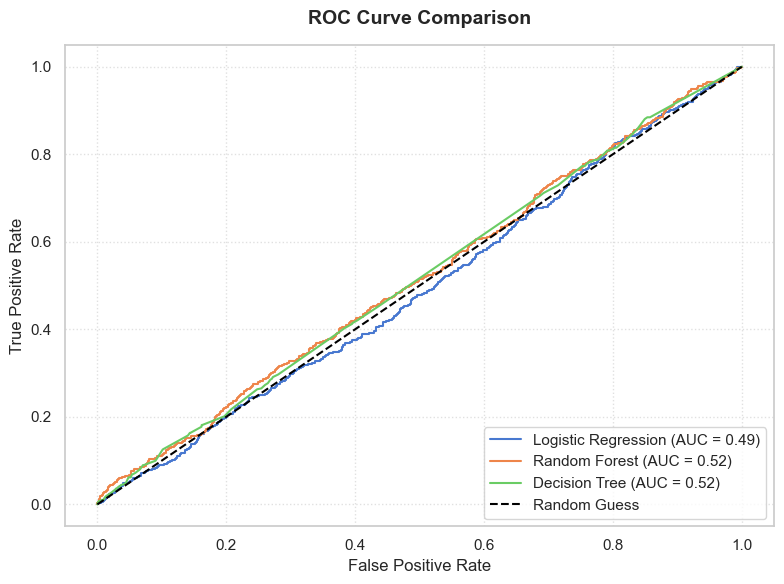

In [199]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_estimator(
    lr,
    X_test_scaled,
    y_test,
    name='Logistic Regression',
    ax=ax
)

RocCurveDisplay.from_estimator(
    rf,
    X_test,
    y_test,
    name='Random Forest',
    ax=ax
)

RocCurveDisplay.from_estimator(
    dt,
    X_test,
    y_test,
    name='Decision Tree',
    ax=ax
)

ax.plot([0, 1], [0, 1], color='black', linestyle='--', label='Random Guess')

ax.set_title("ROC Curve Comparison", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

Analisis Hasil Perbandingan
- Akurasi & Keseluruhan Performa: Random Forest memberikan tingkat akurasi tertinggi. Hal ini dimungkinkan karena algoritma berbasis ensemble tree seperti Random Forest mampu memetakan hubungan non-linear serta interaksi fitur yang kompleks secara lebih baik dibandingkan dengan model linear seperti Logistic Regression. Namun, jika dilihat dari nilai ROC-AUC (0.5163), performa pemisahan kelas kedua model tersebut masih berada di ambang batas tebakan acak (random guess). Kondisi ini merupakan konsekuensi langsung dari distribusi data yang sangat timpang (highly imbalanced dataset), di mana porsi data transaksi fraud hanya sebesar ~5%.
- Dilema Metrik Klasifikasi (Precision vs Recall): Logistic Regression menghasilkan nilai Recall yang cenderung lebih tinggi namun dikombinasikan dengan nilai Precision yang sangat rendah. Karakteristik ini menunjukkan bahwa model linear terlalu sensitif dalam melabeli transaksi sebagai fraud. Dampak operasionalnya adalah tingginya angka False Positive (transaksi normal yang salah dituduh sebagai penipuan), yang berpotensi merugikan kenyamanan pengguna karena akun mereka rentan terblokir secara keliru. Random Forest, di sisi lain, menawarkan titik keseimbangan yang lebih baik melalui nilai Precision yang paling optimal di antara model lainnya. Meskipun nilai Recall-nya lebih rendah, model ini memberikan tingkat kepastian prediktif yang jauh lebih tinggi ketika mendeteksi sebuah transaksi sebagai fraud. Hal ini meminimalkan salah sasaran (False Positive) dan menjaga fungsionalitas sistem perbankan tetap berjalan kondusif bagi nasabah.

Kesimpulan:
1. Karakteristik Imbalance Dataset: Dataset ini bersifat highly imbalanced (sangat tidak seimbang), di mana proporsi transaksi yang dikategorikan sebagai fraud hanya berkisar di angka ~5%, sedangkan ~95% sisanya merupakan transaksi normal. Kondisi ketimpangan kelas ini menjadi tantangan terbesar bagi model untuk mempelajari pola kecurangan secara optimal tanpa terjebak pada bias kelas mayoritas.
2. Perbandingan Performa Model: Tiga model klasifikasi biner telah dilatih dan dibandingkan secara objektif, yaitu Logistic Regression, Random Forest, dan Decision Tree. Berdasarkan metrik evaluasi, Random Forest terbukti memberikan performa keseluruhan yang paling baik dengan tingkat akurasi mencapai 92.64% dan nilai ROC-AUC 0.5163.
3. Keunggulan Algoritma Non-Linear: Random Forest menunjukkan bahwa pola perilaku transaksi keuangan ilegal memiliki struktur hubungan yang bersifat non-linear dan kompleks. Algoritma berbasis ensemble tree ini terbukti jauh lebih handal dalam mengurai interaksi rumit antarfitur seperti nominal uang (Transaction Amount), waktu (Time of Transaction), dan riwayat kecurangan sebelumnya (Previous Fraudulent Transactions) dibandingkan dengan model linear seperti Logistic Regression.
4. Dilema Bisnis dan Operasional (Precision vs Recall): Logistic Regression menghasilkan nilai Recall tinggi namun Precision sangat rendah, yang berarti model ini terlalu sensitif sehingga memicu tingginya angka False Positive. Dalam implementasi nyata, hal ini akan merugikan pelanggan karena akun mereka akan sering terblokir secara keliru oleh sistem keamanan perbankan.

Random Forest menawarkan hasil yang jauh lebih seimbang dengan nilai Precision paling bagus. Model ini memberikan kepastian prediktif yang jauh lebih tinggi dan akurat ketika mendeteksi sebuah transaksi sebagai fraud. Dengan demikian, model ini mampu memitigasi risiko kerugian akibat tindakan kriminal sekaligus meminimalkan salah sasaran pemblokiran demi menjaga kenyamanan bertransaksi masyarakat.